# Titanic Survival Prediction: End-to-End Machine Learning Project

**Problem type:** Binary classification (did a passenger survive? `1` = survived, `0` = did not)
**Dataset:** Titanic passenger data (891 passengers, 15 columns), `data/titanic.csv`
**Models compared:** Logistic Regression, Random Forest, Support Vector Machine (SVM)

**Workflow:**
1. Load & inspect data
2. Exploratory data analysis (EDA)
3. Cleaning & feature engineering
4. Train-test split (stratified)
5. Preprocessing pipeline: missing values, outliers, log transform, encoding, scaling
6. Imbalance handling (SMOTE) & feature selection
7. Model training with hyper-parameter tuning (5-fold cross-validation)
8. Evaluation & visualisations
9. Insights & conclusion

All preprocessing lives inside a scikit-learn/imbalanced-learn `Pipeline`, so every step is **fitted on training data only** (no data leakage).

## 1. Imports & configuration

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, classification_report)
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")

RANDOM_STATE = 42
DATA_PATH = Path("data/titanic.csv")
VISUALS_DIR = Path("visuals")
RESULTS_DIR = Path("results")
VISUALS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

def save_fig(name):
    """Save the current matplotlib figure into visuals/ (used as report screenshots)."""
    plt.savefig(VISUALS_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 2. Load & inspect the data

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


In [4]:
# Missing values per column (count and percentage)
missing = pd.DataFrame({"missing": df.isna().sum(), "percent": (df.isna().mean() * 100).round(1)})
missing[missing["missing"] > 0].sort_values("percent", ascending=False)

,missing,percent
deck,688,77.2
age,177,19.9
embarked,2,0.2
embark_town,2,0.2


`deck` is ~77% missing, which is too sparse to impute reliably, so it will be dropped. `age` (~20%) and `embarked` (2 rows) will be imputed inside the pipeline.

## 3. Exploratory data analysis

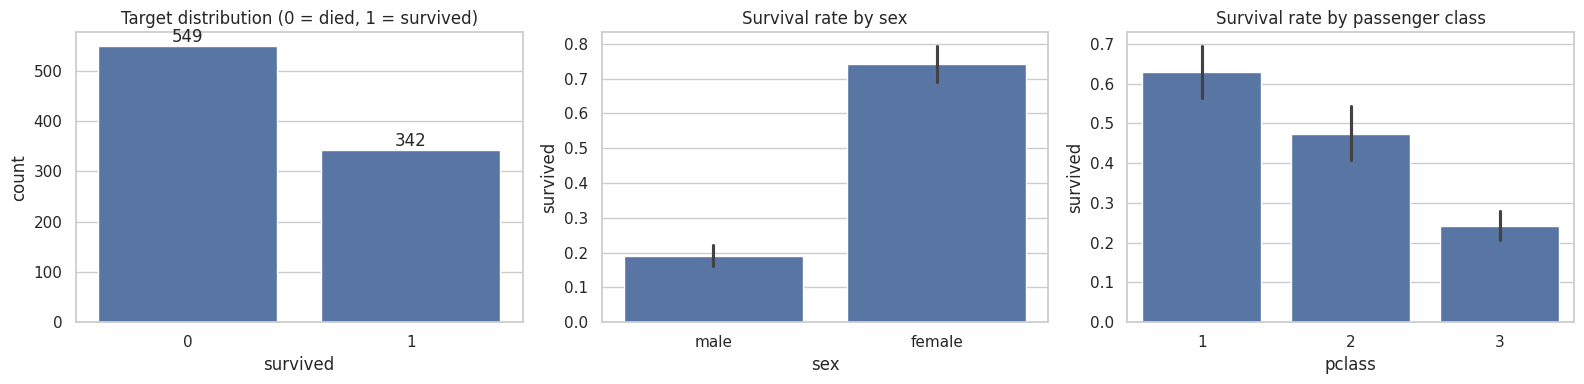

survived
0    0.616
1    0.384
Name: proportion, dtype: float64


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Target distribution -> checks class imbalance
sns.countplot(x="survived", data=df, ax=axes[0])
axes[0].set_title("Target distribution (0 = died, 1 = survived)")
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")

sns.barplot(x="sex", y="survived", data=df, ax=axes[1])
axes[1].set_title("Survival rate by sex")

sns.barplot(x="pclass", y="survived", data=df, ax=axes[2])
axes[2].set_title("Survival rate by passenger class")
plt.tight_layout()
save_fig("01_eda_target_sex_class")
plt.show()

print(df["survived"].value_counts(normalize=True).round(3))

The target is moderately imbalanced (~38% survived / 62% died), so we will use **SMOTE** on the training data and judge models with **F1 and ROC-AUC**, not accuracy alone.

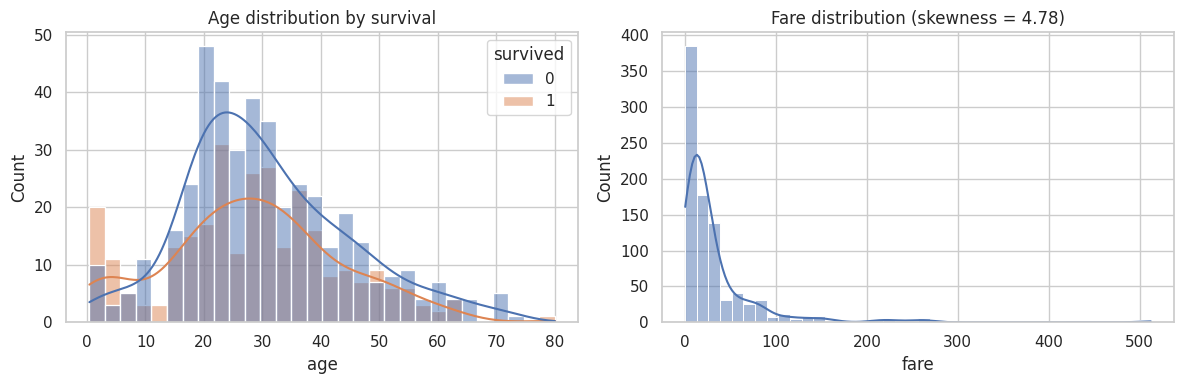

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="age", hue="survived", kde=True, bins=30, ax=axes[0])
axes[0].set_title("Age distribution by survival")
sns.histplot(df["fare"], kde=True, bins=40, ax=axes[1])
axes[1].set_title(f"Fare distribution (skewness = {skew(df['fare']):.2f})")
plt.tight_layout()
save_fig("02_eda_age_fare")
plt.show()

## 4. Cleaning & feature engineering

* **Dropped (data leakage / redundancy):** `alive` (the target as text), `class` (duplicate of `pclass`), `who` and `adult_male` (derived from age/sex), `embark_town` (duplicate of `embarked`), `deck` (77% missing).
* **New features:** `family_size = sibsp + parch + 1` and `is_alone`.

In [7]:
def build_features(raw):
    """Drop leaky/redundant columns and engineer family-related features."""
    data = raw.drop(columns=["alive", "class", "who", "adult_male", "embark_town", "deck", "alone"])
    data["family_size"] = data["sibsp"] + data["parch"] + 1
    data["is_alone"] = (data["family_size"] == 1).astype(int)
    return data

data = build_features(df)
X = data.drop(columns="survived")
y = data["survived"]
print("Features:", list(X.columns))

Features: ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'family_size', 'is_alone']


## 5. Train-test split (stratified 80/20)
Splitting **before** any fitting keeps the test set unseen. `stratify=y` preserves the class ratio in both sets.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print("Train survival rate:", round(y_train.mean(), 3), "| Test survival rate:", round(y_test.mean(), 3))

Train: (712, 9), Test: (179, 9)
Train survival rate: 0.383 | Test survival rate: 0.385


## 6. Outlier detection (IQR method)
Values outside `[Q1 - 1.5·IQR, Q3 + 1.5·IQR]` are flagged as outliers. Computed on the **training set** only.

In [9]:
def iqr_bounds(series, k=1.5):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

outlier_cols = ["age", "fare", "sibsp", "parch", "family_size"]
summary = []
for col in outlier_cols:
    lo, hi = iqr_bounds(X_train[col].dropna())
    n_out = ((X_train[col] < lo) | (X_train[col] > hi)).sum()
    summary.append({"feature": col, "lower": round(lo, 2), "upper": round(hi, 2),
                    "n_outliers": n_out, "percent": round(100 * n_out / len(X_train), 1)})
pd.DataFrame(summary)

,feature,lower,upper,n_outliers,percent
0,age,-6.00,66.00,6,0.8
1,fare,-26.76,65.66,91,12.8
2,sibsp,-1.50,2.50,33,4.6
3,parch,0.00,0.00,170,23.9
4,family_size,-0.50,3.50,72,10.1


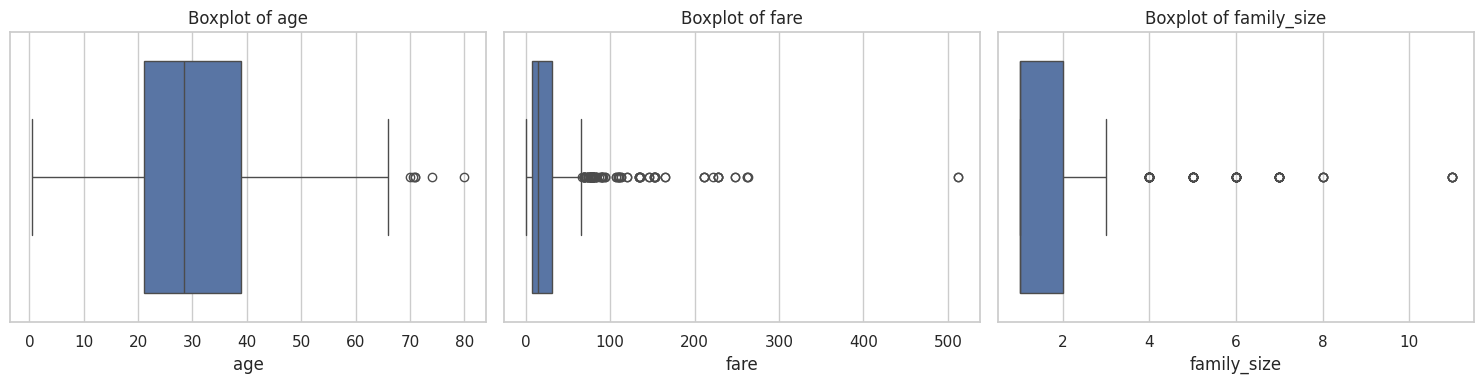

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["age", "fare", "family_size"]):
    sns.boxplot(x=X_train[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")
plt.tight_layout()
save_fig("03_outlier_boxplots")
plt.show()

**Treatment: winsorisation (capping).** Rather than deleting passengers (which would shrink an already small dataset), extreme values are capped at the IQR bounds. This is implemented as a reusable transformer so the bounds are learned from training data only.

In [11]:
class IQRCapper(BaseEstimator, TransformerMixin):
    """Cap values to [Q1 - k*IQR, Q3 + k*IQR]; bounds are learned in fit() from training data."""

    def __init__(self, k=1.5):
        self.k = k

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1, q3 = np.nanpercentile(X, 25, axis=0), np.nanpercentile(X, 75, axis=0)
        iqr = q3 - q1
        self.lower_, self.upper_ = q1 - self.k * iqr, q3 + self.k * iqr
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

## 7. Data transformation: skewed `fare`
`fare` is strongly right-skewed. A `log1p` transform (log(1 + x), safe for zeros) makes it far more symmetric, which helps Logistic Regression and SVM.

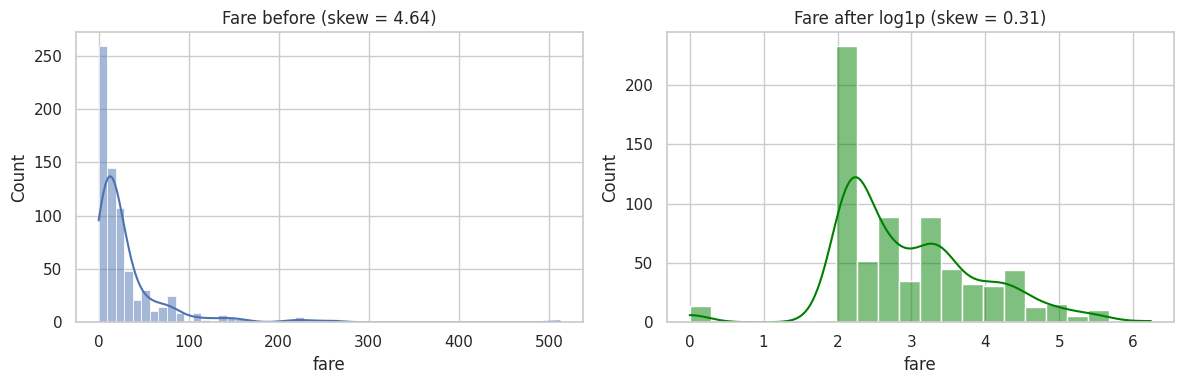

In [12]:
fare_log = np.log1p(X_train["fare"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(X_train["fare"], kde=True, ax=axes[0]).set_title(f"Fare before (skew = {skew(X_train['fare']):.2f})")
sns.histplot(fare_log, kde=True, ax=axes[1], color="green").set_title(f"Fare after log1p (skew = {skew(fare_log):.2f})")
plt.tight_layout()
save_fig("04_fare_log_transform")
plt.show()

## 8. Preprocessing pipeline
| Feature group | Steps |
|---|---|
| `fare` | median impute → IQR cap → `log1p` → standardise |
| `age, sibsp, parch, family_size` | median impute → IQR cap → standardise |
| `sex, embarked, pclass` | most-frequent impute → one-hot encode |
| `is_alone` (binary) | passed through |

In [13]:
def build_preprocessor():
    """ColumnTransformer handling missing values, outliers, log transform, scaling and encoding."""
    fare_pipe = ImbPipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("cap", IQRCapper()),
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])
    numeric_pipe = ImbPipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("cap", IQRCapper()),
        ("scale", StandardScaler()),
    ])
    categorical_pipe = ImbPipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("fare", fare_pipe, ["fare"]),
        ("num", numeric_pipe, ["age", "sibsp", "parch", "family_size"]),
        ("cat", categorical_pipe, ["sex", "embarked", "pclass"]),
        ("bin", "passthrough", ["is_alone"]),
    ], verbose_feature_names_out=False)

preprocessor = build_preprocessor()
X_train_prep = preprocessor.fit_transform(X_train)
feature_names = preprocessor.get_feature_names_out()
print("Features after preprocessing:", len(feature_names))
print("Missing values left:", int(np.isnan(np.asarray(X_train_prep, dtype=float)).sum()))
pd.DataFrame(X_train_prep, columns=feature_names).head()

Features after preprocessing: 14
Missing values left: 0


,fare,age,sibsp,parch,family_size,sex_female,sex_male,embarked_C,embarked_Q,embarked_S,pclass_1,pclass_2,pclass_3,is_alone
0,1.375030,-0.065863,-0.588661,0.0,-0.716839,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
1,-3.392626,-0.065863,-0.588661,0.0,-0.716839,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
2,1.548991,-0.065863,-0.588661,0.0,-0.716839,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
3,-0.642690,-0.914811,-0.588661,0.0,0.385514,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,0.496436,0.136268,0.864117,0.0,1.487867,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


## 9. Feature selection
ANOVA F-scores (`f_classif`) rank how strongly each processed feature separates survivors from non-survivors. The pipeline keeps the **top 10** features.

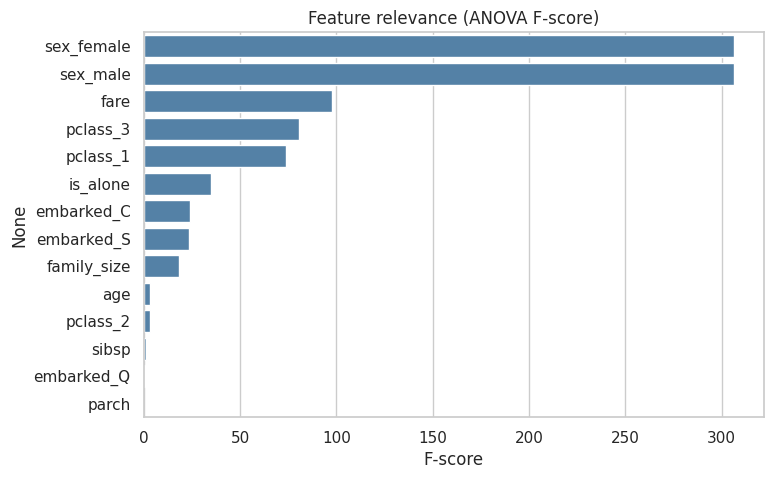

In [14]:
scores = pd.Series(f_classif(X_train_prep, y_train)[0], index=feature_names).sort_values(ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(x=scores.values, y=scores.index, color="steelblue")
plt.title("Feature relevance (ANOVA F-score)")
plt.xlabel("F-score")
save_fig("05_feature_selection_scores")
plt.show()

## 10. Model training & hyper-parameter tuning
Three models with different strengths:
* **Logistic Regression**: simple, interpretable linear baseline.
* **Random Forest**: non-linear, robust to outliers, gives feature importances.
* **SVM (RBF kernel)**: strong on small, well-scaled datasets.

Each model is wrapped in `preprocess → SMOTE → SelectKBest → model` and tuned with `GridSearchCV` (5-fold stratified CV, scored on F1). SMOTE is applied **only to training folds** inside the pipeline.

In [15]:
def build_pipeline(model):
    """Full pipeline: preprocessing -> SMOTE oversampling -> feature selection -> classifier."""
    return ImbPipeline([
        ("prep", build_preprocessor()),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("select", SelectKBest(f_classif, k=10)),
        ("model", model),
    ])

search_space = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
                            {"model__C": [0.01, 0.1, 1, 10]}),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE),
                      {"model__n_estimators": [200, 400],
                       "model__max_depth": [4, 6, 8, None],
                       "model__min_samples_leaf": [1, 3, 5]}),
    "SVM (RBF)": (SVC(probability=True, random_state=RANDOM_STATE),
                  {"model__C": [0.5, 1, 5, 10],
                   "model__gamma": ["scale", 0.05, 0.1]}),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
best_models, best_params, cv_f1 = {}, {}, {}

for name, (model, grid) in search_space.items():
    search = GridSearchCV(build_pipeline(model), grid, scoring="f1", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    best_params[name] = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    cv_f1[name] = search.best_score_
    print(f"{name:20s} best CV F1 = {search.best_score_:.4f} | params = {best_params[name]}")

Logistic Regression  best CV F1 = 0.7304 | params = {'C': 10}


Random Forest        best CV F1 = 0.7465 | params = {'max_depth': 8, 'min_samples_leaf': 5, 'n_estimators': 400}


SVM (RBF)            best CV F1 = 0.7431 | params = {'C': 10, 'gamma': 0.05}


## 11. Evaluation on the held-out test set

In [16]:
def evaluate_model(name, model, X_eval, y_eval):
    """Return a dict of classification metrics for a fitted model."""
    pred = model.predict(X_eval)
    proba = model.predict_proba(X_eval)[:, 1]
    return {
        "Model": name,
        "CV F1 (train)": round(cv_f1[name], 4),
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred),
        "Recall": recall_score(y_eval, pred),
        "F1 Score": f1_score(y_eval, pred),
        "ROC-AUC": roc_auc_score(y_eval, proba),
    }

results = pd.DataFrame([evaluate_model(n, m, X_test, y_test) for n, m in best_models.items()])
results = results.set_index("Model").round(4).sort_values("F1 Score", ascending=False)
results.to_csv(RESULTS_DIR / "model_comparison.csv")
pd.Series({k: str(v) for k, v in best_params.items()}).to_json(RESULTS_DIR / "best_params.json", indent=2)
results

,CV F1 (train),Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,,
SVM (RBF),0.7431,0.7989,0.7089,0.8116,0.7568,0.8580
Logistic Regression,0.7304,0.7821,0.6923,0.7826,0.7347,0.8225
Random Forest,0.7465,0.7877,0.7246,0.7246,0.7246,0.8417


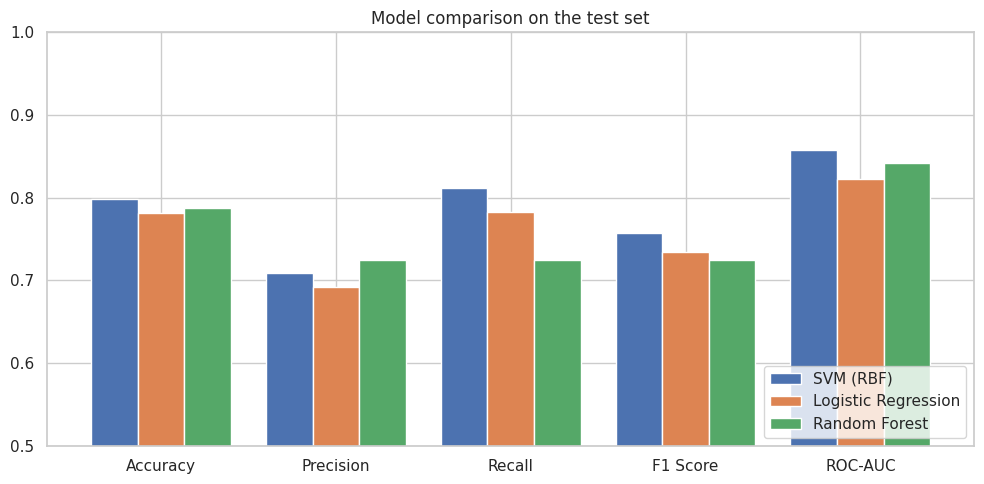

In [17]:
# Visual metric comparison
metric_cols = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
ax = results[metric_cols].T.plot(kind="bar", figsize=(10, 5), rot=0, width=0.8)
ax.set_ylim(0.5, 1.0)
ax.set_title("Model comparison on the test set")
ax.legend(loc="lower right")
plt.tight_layout()
save_fig("06_model_comparison")
plt.show()

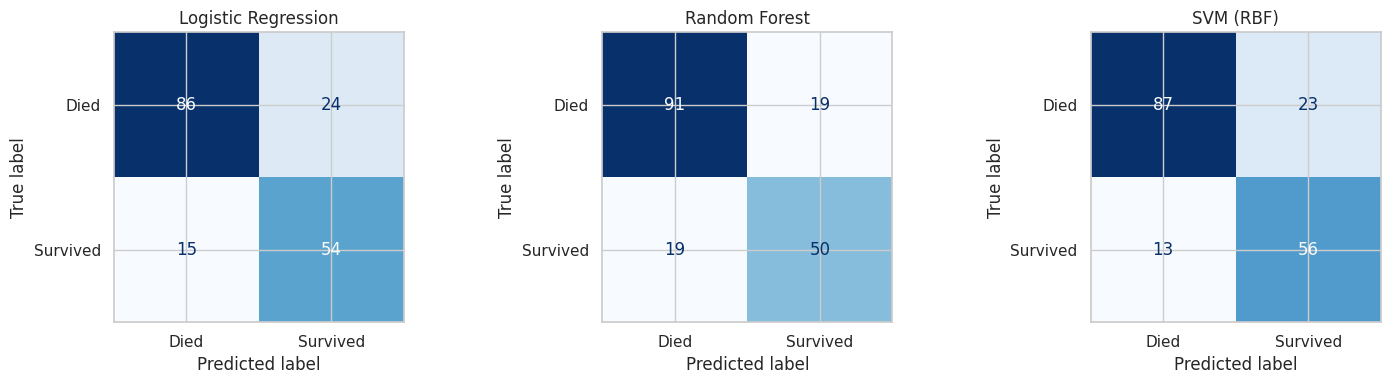

In [18]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, best_models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=["Died", "Survived"],
                                          cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
save_fig("07_confusion_matrices")
plt.show()

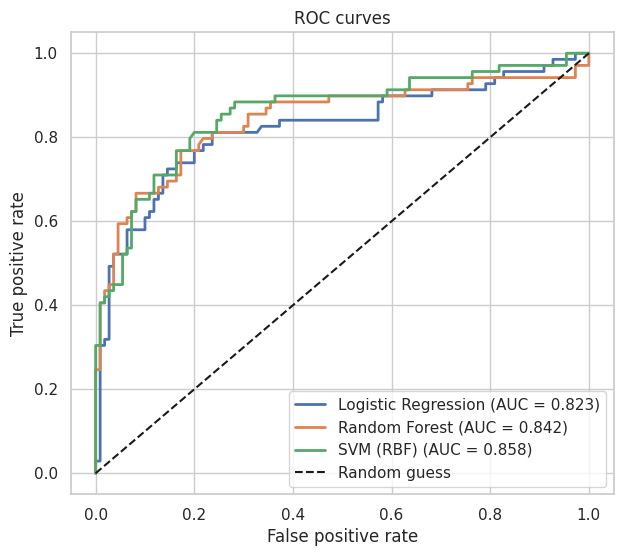

In [19]:
# ROC curves
plt.figure(figsize=(7, 6))
for name, model in best_models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {results.loc[name, 'ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves")
plt.legend(loc="lower right")
save_fig("08_roc_curves")
plt.show()

In [20]:
# Detailed report for the best model
best_name = results.index[0]
print("Best model:", best_name)
print(classification_report(y_test, best_models[best_name].predict(X_test), target_names=["Died", "Survived"]))

Best model: SVM (RBF)
              precision    recall  f1-score   support

        Died       0.87      0.79      0.83       110
    Survived       0.71      0.81      0.76        69

    accuracy                           0.80       179
   macro avg       0.79      0.80      0.79       179
weighted avg       0.81      0.80      0.80       179



## 12. Model interpretation

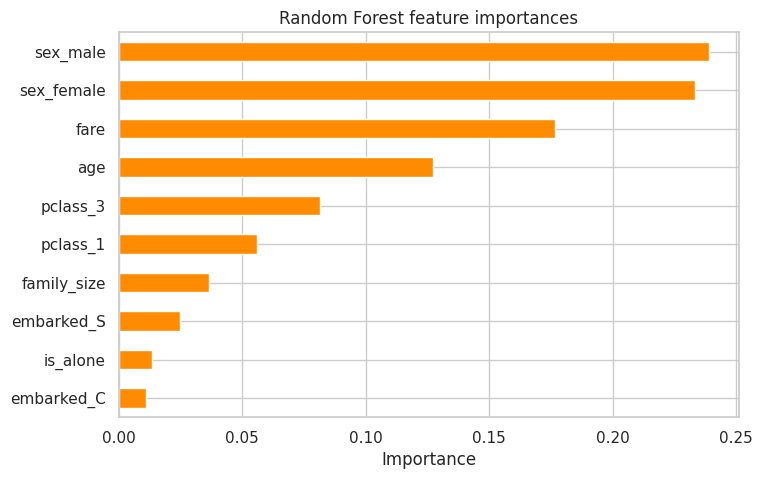

In [21]:
# Random Forest feature importances (names must follow SelectKBest's selection)
rf_pipe = best_models["Random Forest"]
selected = np.asarray(rf_pipe.named_steps["prep"].get_feature_names_out())[rf_pipe.named_steps["select"].get_support()]
importances = pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=selected).sort_values()

plt.figure(figsize=(8, 5))
importances.plot(kind="barh", color="darkorange")
plt.title("Random Forest feature importances")
plt.xlabel("Importance")
save_fig("09_rf_feature_importance")
plt.show()

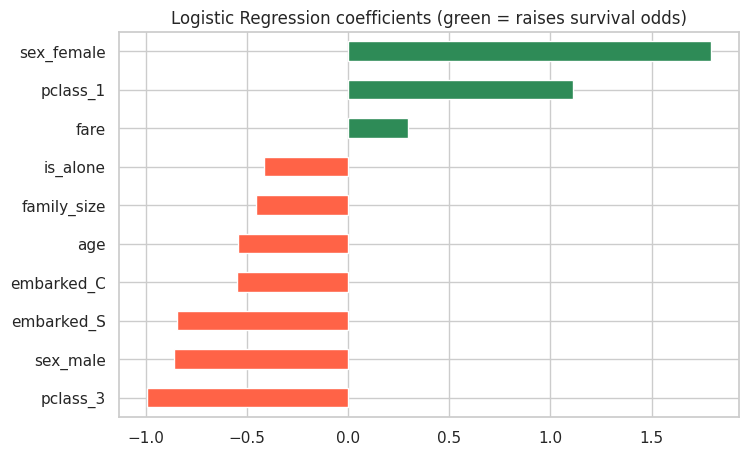

In [22]:
# Logistic Regression coefficients: direction of each feature's effect
lr_pipe = best_models["Logistic Regression"]
lr_features = np.asarray(lr_pipe.named_steps["prep"].get_feature_names_out())[lr_pipe.named_steps["select"].get_support()]
coefs = pd.Series(lr_pipe.named_steps["model"].coef_[0], index=lr_features).sort_values()

plt.figure(figsize=(8, 5))
coefs.plot(kind="barh", color=["tomato" if c < 0 else "seagreen" for c in coefs])
plt.title("Logistic Regression coefficients (green = raises survival odds)")
save_fig("10_lr_coefficients")
plt.show()

## 13. Key insights & conclusion
* **Sex is the strongest predictor of survival**, followed by `fare`, `age` and passenger class (Random Forest importances and Logistic Regression coefficients agree). This matches the "women and children first" rule and class-based access to lifeboats.
* **Family variables (`family_size`, `is_alone`) carry a smaller but non-zero signal**, and port of embarkation adds little.
* **Best model: SVM (RBF).** It achieved the highest test F1 (0.757) and ROC-AUC (0.858) with the best recall (0.812). Random Forest had the best cross-validated F1 and good precision; Logistic Regression is the most interpretable baseline. Differences are small, so on a test set of only 179 passengers they should not be over-interpreted.
* **Leakage-free design.** Imputation, capping, log transform, scaling, SMOTE and feature selection are all fitted inside the pipeline on training folds only.
* **Limitations & future work:** only 891 rows; `age` was median-imputed; I did not run an ablation to isolate the effect of SMOTE or outlier capping. Extracting a title from passenger names, adding cabin deck and trying XGBoost / LightGBM are natural next steps.